In [ ]:
from tensorflow.keras.datasets import reuters
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, LSTM, Embedding, SimpleRNN
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras.models import load_model
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

In [ ]:
## Reuters data set 불러오기
(X_train, y_train), (X_test, y_test) = reuters.load_data(num_words=1000, test_split=0.2, seed=123)

In [ ]:
## 데이터 들여다보기
print('Number of train samples: %d'%len(X_train))
print('Number of test samples: %d'%len(X_test))
print('An example of the reuters data set')
print('...Input sample')
print(X_train[0])
print(len(X_train[0]))
print('...Output samples (10)')
print(y_train[0:10])
print('Number of categories: %d'%(y_test.max()+1))

Number of train samples: 8982
Number of test samples: 2246
An example of the reuters data set
...Input sample
[1, 599, 2, 9, 2, 764, 2, 56, 2, 2, 8, 25, 2, 61, 20, 324, 323, 56, 2, 2, 2, 200, 6, 264, 342, 2, 2, 9, 2, 2, 56, 2, 22, 56, 2, 71, 10, 2, 176, 487, 6, 658, 231, 783, 51, 8, 775, 5, 2, 34, 69, 251, 11, 599, 505, 2, 4, 2, 2, 2, 7, 4, 2, 9, 2, 2, 17, 12]
68
...Output samples (10)
[ 4  4 19 25 22  3  3  3  3  3]
Number of categories: 46


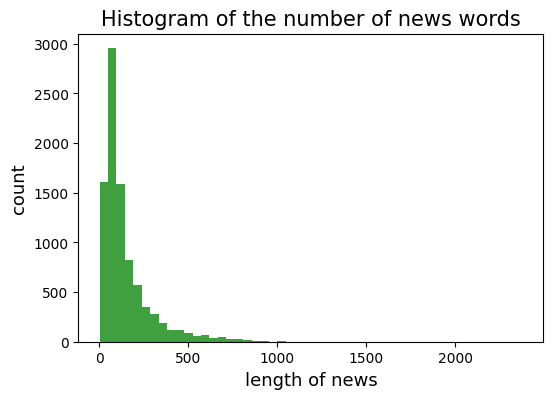

In [ ]:
## 뉴스의 단어 수에 대한 히스토그램 그려보기
plt.figure(figsize=(6,4))
n, bins, patches = plt.hist(np.hstack([len(x) for x in X_train]), 50, facecolor='g', alpha=0.75)
plt.xlabel('length of news', fontsize=13)
plt.ylabel('count', fontsize=13)
plt.title('Histogram of the number of news words', fontsize=15)
plt.show()

In [ ]:
unique_elements, counts_elements = np.unique(y_train, return_counts=True)
print("각 레이블에 대한 빈도수:")
print(np.vstack((unique_elements, counts_elements)))

각 레이블에 대한 빈도수:
[[   0    1    2    3    4    5    6    7    8    9   10   11   12   13
    14   15   16   17   18   19   20   21   22   23   24   25   26   27
    28   29   30   31   32   33   34   35   36   37   38   39   40   41
    42   43   44   45]
 [  54  421   76 3198 1916   17   50   15  135   96  118  374   52  179
    23   28  438   41   64  552  282  104   18   43   62  106   25   12
    45   19   40   45   30   15   47   10   44   20   13   20   39   32
    12   21   16   15]]


In [ ]:
word_to_index = reuters.get_word_index()
print(word_to_index)

index_to_word={}
## switching key and value in dictionary
for key, value in word_to_index.items():
    index_to_word[value] = key

print(index_to_word)

## 빈도수 index번째 단어 살펴보기
index=5
print('빈도수 상위'+str(index)+'번째 단어 : {}'.format(index_to_word[index]))

## 복원된 문장 만들어보기
print(X_train[0])
print(' '.join([index_to_word[s] for s in X_train[0]]))



{'mdbl': 10996, 'fawc': 16260, 'degussa': 12089, 'woods': 8803, 'hanging': 13796, 'localized': 20672, 'sation': 20673, 'chanthaburi': 20675, 'refunding': 10997, 'hermann': 8804, 'passsengers': 20676, 'stipulate': 20677, 'heublein': 8352, 'screaming': 20713, 'tcby': 16261, 'four': 185, 'grains': 1642, 'broiler': 20680, 'wooden': 12090, 'wednesday': 1220, 'highveld': 13797, 'duffour': 7593, '0053': 20681, 'elections': 3914, '270': 2563, '271': 3551, '272': 5113, '273': 3552, '274': 3400, 'rudman': 7975, '276': 3401, '277': 3478, '278': 3632, '279': 4309, 'dormancy': 9381, 'errors': 7247, 'deferred': 3086, 'sptnd': 20683, 'cooking': 8805, 'stratabit': 20684, 'designing': 16262, 'metalurgicos': 20685, 'databank': 13798, '300er': 20686, 'shocks': 20687, 'nawg': 7972, 'tnta': 20688, 'perforations': 20689, 'affiliates': 2891, '27p': 20690, 'ching': 16263, 'china': 595, 'wagyu': 16264, 'affiliated': 3189, 'chino': 16265, 'chinh': 16266, 'slickline': 20692, 'doldrums': 13799, 'kids': 12092, 'cl

In [ ]:
## 뉴스를 구성하는 단어의 수 일치시키기.
max_len = 100  ## 최대 100개

pad_X_train = pad_sequences(X_train, maxlen=max_len) # train set
pad_X_test = pad_sequences(X_test, maxlen=max_len)   # test set

print(X_train[0])
print(pad_X_train[0])

## one hot coding
oh_y_train = to_categorical(y_train)
oh_y_test = to_categorical(y_test)

print(y_train[0])
print(oh_y_train[0])


[1, 599, 2, 9, 2, 764, 2, 56, 2, 2, 8, 25, 2, 61, 20, 324, 323, 56, 2, 2, 2, 200, 6, 264, 342, 2, 2, 9, 2, 2, 56, 2, 22, 56, 2, 71, 10, 2, 176, 487, 6, 658, 231, 783, 51, 8, 775, 5, 2, 34, 69, 251, 11, 599, 505, 2, 4, 2, 2, 2, 7, 4, 2, 9, 2, 2, 17, 12]
[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   1 599   2   9
   2 764   2  56   2   2   8  25   2  61  20 324 323  56   2   2   2 200
   6 264 342   2   2   9   2   2  56   2  22  56   2  71  10   2 176 487
   6 658 231 783  51   8 775   5   2  34  69 251  11 599 505   2   4   2
   2   2   7   4   2   9   2   2  17  12]
4
[0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


In [ ]:
## 1-layered rnn
rnn = Sequential()
rnn.add(Embedding(1000, 100))
#rnn.add(SimpleRNN(50, return_sequences = True, activation='tanh'))   # return_sequences parameter has to be set True to stack
rnn.add(SimpleRNN(50, return_sequences = False, activation='tanh'))
rnn.add(Dense(46, activation = 'softmax'))

## 1-layered lstm
lstm = Sequential()
lstm.add(Embedding(1000, 100))
#lstm.add(LSTM(100, activation='tanh', return_sequences=True))
lstm.add(LSTM(100, activation='tanh'))
lstm.add(Dense(46, activation = 'softmax'))

## model compile
rnn.compile(loss = 'categorical_crossentropy', optimizer = 'adam', metrics = ['accuracy'])
lstm.compile(loss = 'categorical_crossentropy', optimizer = 'adam', metrics = ['accuracy'])

## start training
rnn_history = rnn.fit(pad_X_train, oh_y_train, batch_size = 100, epochs = 20, validation_split=0.10)
lstm_history = lstm.fit(pad_X_train, oh_y_train, batch_size = 100, epochs = 20, validation_split=0.10)


Epoch 1/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.3510 - loss: 2.6139 - val_accuracy: 0.3904 - val_loss: 2.1633
Epoch 2/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.4653 - loss: 2.0504 - val_accuracy: 0.4383 - val_loss: 1.9758
Epoch 3/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.4747 - loss: 1.9836 - val_accuracy: 0.4672 - val_loss: 1.9060
Epoch 4/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.5275 - loss: 1.8081 - val_accuracy: 0.5161 - val_loss: 1.7791
Epoch 5/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.5638 - loss: 1.6988 - val_accuracy: 0.5539 - val_loss: 1.6973
Epoch 6/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.5961 - loss: 1.6298 - val_accuracy: 0.5395 - val_loss: 1.7324
Epoch 7/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.6171 - loss: 1.5498 - val_accuracy: 0.5651 - val_loss: 1.6537
Epoch 8/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.6496 - loss: 1.4430 - val_accuracy: 0.5651 - v

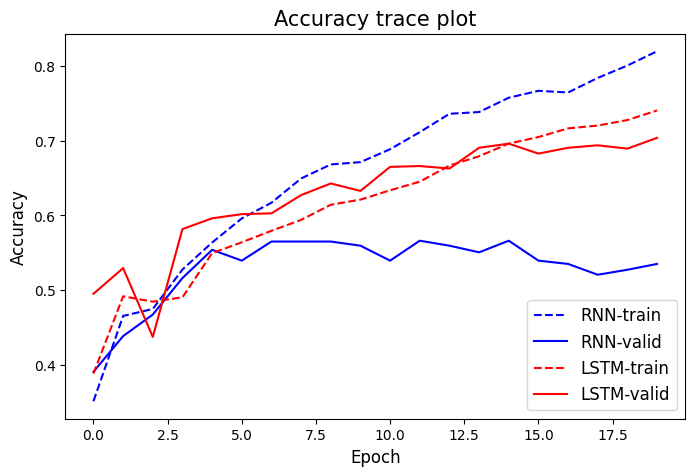

71/71 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4951 - loss: 2.2980
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.6719 - loss: 1.3219
...RNN accuracy: 0.495, loss: 2.298
...LSTM accuracy: 0.672, loss: 1.322


In [ ]:
plt.figure(figsize=(8,5))
plt.plot(rnn_history.history['accuracy'], 'b--', label='RNN-train')
plt.plot(rnn_history.history['val_accuracy'], 'b-', label='RNN-valid')
plt.plot(lstm_history.history['accuracy'], 'r--', label='LSTM-train')
plt.plot(lstm_history.history['val_accuracy'], 'r-', label='LSTM-valid')
plt.xlabel('Epoch', fontsize=12)
plt.ylabel('Accuracy', fontsize=12)
plt.legend(loc='lower right', fontsize=12)
plt.title('Accuracy trace plot', fontsize=15)
plt.show()

rnn_results = rnn.evaluate(pad_X_test, oh_y_test)
lstm_results = lstm.evaluate(pad_X_test, oh_y_test)
print('...RNN accuracy: %.3f, loss: %.3f'%(rnn_results[1], rnn_results[0]))
print('...LSTM accuracy: %.3f, loss: %.3f'%(lstm_results[1], lstm_results[0]))

# 하이퍼파라미터별 비교 실험: 총 20개 실행 그룹
먼저 아래 **공통 설정**과 **공통 함수** 셀을 한 번씩 실행하세요. 기존 앞부분의 학습 셀은 실행하지 않아도 됩니다.
그다음 원하는 모델·파라미터의 실행 셀만 선택해서 실행하세요. 다른 19개 그룹은 자동 실행되지 않습니다.
각 그룹에서 기준 모델과 해당 파라미터 후보를 비교하고 테스트 결과 표 및 학습·검증 Accuracy Trace Plot을 표시합니다.
기준 모델은 RNN 노드 50개, LSTM 노드 100개이며, 다른 값은 기존 기준 설정을 사용합니다.
기준 모델을 포함해 총 32개 고유 설정(RNN 16개 + LSTM 16개)입니다. 같은 커널에서 이미 완료한 설정은 결과와 그래프 이력을 재사용합니다.
다시 학습하려면 실행 함수에 `rerun=True`를 추가하세요. 커널을 재시작하거나 공통 설정을 다시 실행하면 메모리의 재사용 이력이 초기화됩니다.
결과는 작업 디렉터리의 `hyperparameter_results` 폴더에 CSV와 PNG로 저장합니다. 파일은 같은 이름으로 다시 저장하면 덮어씁니다.
테스트 결과로 설정을 선택하면 테스트 데이터도 모델 선택에 사용된 것이므로 최종 성능을 해석할 때 고려해야 합니다.


## 공통 설정: 라이브러리와 기준값·후보

In [ ]:
import os
import warnings
import logging

# TensorFlow 경고 로그를 숨기고 실제 오류는 표시합니다.
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
logging.getLogger('tensorflow').setLevel(logging.ERROR)

warnings.filterwarnings(
    'ignore',
    message=r'dtype\(\): align should be passed as Python or NumPy boolean.*',
)

from pathlib import Path
import csv
import gc
import time

import numpy as np
import pandas as pd
import tensorflow as tf
tf.get_logger().setLevel(logging.ERROR)
tf.autograph.set_verbosity(0)
from tensorflow.keras import Sequential
from tensorflow.keras.datasets import reuters
from tensorflow.keras.layers import Input, Embedding, SimpleRNN, LSTM, Dropout, Dense
from tensorflow.keras.optimizers import Adam, RMSprop, SGD
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.utils import to_categorical

SEED = 123
RESULTS_PATH = Path('hyperparameter_test_results.csv')

BASE = dict(
    max_len=100, layers=1, units=50, optimizer='Adam',
    num_words=1000, embedding_dim=100, learning_rate=0.001,
    batch_size=100, dropout=0.0, epochs=20,
)
CANDIDATES = {
    'max_len': [100, 200, 500],
    'layers': [1, 2],
    'units': [32, 50, 100],
    'optimizer': ['Adam', 'RMSprop', 'MomentumSGD'],
    'num_words': [1000, 5000],
    'embedding_dim': [32, 100],
    'learning_rate': [0.0001, 0.001, 0.01],
    'batch_size': [32, 100, 256],
    'dropout': [0.0, 0.2],
    'epochs': [20, 40],
}


import math
import matplotlib.pyplot as plt

# 완료한 모델의 평가 결과와 학습 이력을 보관합니다. 공통 설정 셀을 다시 실행하면 초기화됩니다.
EXPERIMENT_CACHE = {}
RESULTS_DIR = Path('hyperparameter_results')
RESULTS_DIR.mkdir(exist_ok=True)


## 공통 함수: 모델 구성 및 그룹별 실행

In [ ]:
def make_optimizer(config):
    lr = config['learning_rate']
    return {
        'Adam': lambda: Adam(learning_rate=lr),
        'RMSprop': lambda: RMSprop(learning_rate=lr),
        'SGD': lambda: SGD(learning_rate=lr),
        'MomentumSGD': lambda: SGD(learning_rate=lr, momentum=0.9),
    }[config['optimizer']]()


def build_model(model_type, config):
    recurrent_layer = SimpleRNN if model_type == 'RNN' else LSTM
    model = Sequential([
        Input(shape=(config['max_len'],), dtype='int32'),
        Embedding(config['num_words'], config['embedding_dim']),
    ])
    for layer_index in range(config['layers']):
        model.add(recurrent_layer(
            config['units'], activation='tanh',
            return_sequences=layer_index < config['layers'] - 1,
        ))
    if config['dropout'] > 0:
        model.add(Dropout(config['dropout']))
    model.add(Dense(46, activation='softmax'))
    model.compile(
        optimizer=make_optimizer(config),
        loss='categorical_crossentropy', metrics=['accuracy'],
    )
    return model


def load_experiment_data(config):
    # 어휘 수를 바꾸어도 같은 뉴스가 같은 순서로 학습·테스트에 배정되도록 시드를 고정합니다.
    (x_train, y_train), (x_test, y_test) = reuters.load_data(
        num_words=config['num_words'], test_split=0.2, seed=SEED,
    )
    x_train = pad_sequences(x_train, maxlen=config['max_len'],
                            padding='pre', truncating='pre')
    x_test = pad_sequences(x_test, maxlen=config['max_len'],
                           padding='pre', truncating='pre')
    return (x_train, to_categorical(y_train, num_classes=46),
            x_test, to_categorical(y_test, num_classes=46))



def run_parameter_experiments(model_type, parameter, rerun=False):
    """모델 하나와 파라미터 하나의 후보만 비교합니다. rerun=True이면 다시 학습합니다."""
    baseline = {**BASE, 'units': 50 if model_type == 'RNN' else 100}
    # 각 그룹에 기준 모델을 포함하되, 이미 완료한 설정은 다시 학습하지 않습니다.
    configs = [baseline] + [
        {**baseline, parameter: value}
        for value in CANDIDATES[parameter] if value != baseline[parameter]
    ]
    group_rows, plot_data = [], []
    print(f'\n{model_type} / {parameter}: {len(configs)}개 설정 비교')
    for number, config in enumerate(configs, 1):
        is_baseline = config == baseline
        name = f'{model_type}__baseline' if is_baseline else f'{model_type}__{parameter}_{config[parameter]}'
        key = (model_type, tuple(sorted(config.items())))
        reused = key in EXPERIMENT_CACHE and not rerun
        if not reused:
            tf.keras.backend.clear_session()
            gc.collect()
            tf.keras.utils.set_random_seed(SEED)
            started = time.perf_counter()
            model, history_data = None, None
            row = dict(model_type=model_type, model_name=name, **config)
            print(f'[{number}/{len(configs)}] {name} 학습 시작', flush=True)
            try:
                x_train, y_train, x_test, y_test = load_experiment_data(config)
                model = build_model(model_type, config)
                history = model.fit(
                    x_train, y_train, batch_size=config['batch_size'],
                    epochs=config['epochs'], validation_split=0.10,
                    shuffle=True, verbose=0,
                )
                history_data = history.history
                scores = model.evaluate(x_test, y_test, verbose=0, return_dict=True)
                loss, accuracy = float(scores['loss']), float(scores['accuracy'])
                finite = np.isfinite(loss) and np.isfinite(accuracy)
                row.update(test_loss=loss, test_accuracy=accuracy,
                           status='ok' if finite else 'non_finite', error='')
            except (tf.errors.OpError, ValueError) as exc:
                row.update(test_loss=np.nan, test_accuracy=np.nan,
                           status='failed', error=str(exc).replace('\n', ' ')[:500])
            row['seconds'] = time.perf_counter() - started
            if row['status'] == 'ok':
                EXPERIMENT_CACHE[key] = (row, history_data)
                # 실험이 완료될 때마다 결과를 저장합니다.
                pd.DataFrame([item[0] for item in EXPERIMENT_CACHE.values()]).to_csv(
                    RESULTS_DIR / 'all_completed_results.csv', index=False, encoding='utf-8-sig',
                )
            del model
            tf.keras.backend.clear_session()
            gc.collect()
        else:
            row, history_data = EXPERIMENT_CACHE[key]
        group_rows.append(dict(row))
        plot_data.append((name, history_data))
        suffix = '(기존 결과 재사용)' if reused else ''
        print(f"[{number}/{len(configs)}] {name}: 테스트 손실={row['test_loss']:.4f}, "
              f"테스트 정확도={row['test_accuracy']:.2%}, 소요 시간={row['seconds']:.1f}초 {suffix}", flush=True)
        if row['status'] != 'ok':
            print(f"상태: {row['status']} {row['error']}")

    frame = pd.DataFrame(group_rows)
    baseline_score = frame.iloc[0]['test_accuracy']
    frame['difference_pp'] = 100 * (frame['test_accuracy'] - baseline_score)
    frame.to_csv(RESULTS_DIR / f'{model_type}__{parameter}.csv', index=False, encoding='utf-8-sig')
    shown = frame[['model_name', 'test_loss', 'test_accuracy', 'difference_pp', 'seconds', 'status']].rename(columns={
        'model_name': '모델명', 'test_loss': '테스트 손실', 'test_accuracy': '테스트 정확도',
        'difference_pp': '기준 대비 차이(%p)', 'seconds': '학습·평가 시간(초)', 'status': '상태',
    })
    print('\n테스트 결과 (기준 대비 차이는 정확도의 퍼센트포인트 차이)')
    print(shown.to_string(index=False, formatters={
        '테스트 손실': '{:.4f}'.format, '테스트 정확도': '{:.2%}'.format,
        '기준 대비 차이(%p)': '{:+.2f}'.format, '학습·평가 시간(초)': '{:.1f}'.format,
    }))

    # 모든 후보를 하나의 그래프에 표시합니다. 같은 후보는 같은 색상을 사용합니다.
    # 학습 정확도는 점선, 검증 정확도는 실선으로 구분합니다.
    fig, ax = plt.subplots(figsize=(10, 6))
    colors = plt.get_cmap('tab10')
    for index, (name, history_data) in enumerate(plot_data):
        if history_data is None:
            continue
        epochs = range(1, len(history_data['accuracy']) + 1)
        color = colors(index % 10)
        ax.plot(epochs, history_data['accuracy'], linestyle='--',
                color=color, label=f'{name}-train')
        ax.plot(epochs, history_data['val_accuracy'], linestyle='-',
                color=color, label=f'{name}-valid')
    ax.set_xlabel('Epoch', fontsize=12)
    ax.set_ylabel('Accuracy', fontsize=12)
    ax.set_ylim(0, 1)
    ax.set_title(f'{model_type} / {parameter} - Accuracy trace plot', fontsize=15)
    ax.grid(alpha=0.3)
    if ax.lines:
        ax.legend(loc='lower right', fontsize=8)
    fig.tight_layout()
    fig.savefig(RESULTS_DIR / f'{model_type}__{parameter}_accuracy.png', dpi=150)
    plt.show()
    return frame


## 01. RNN — 최대 길이
이 셀은 RNN의 `max_len` 후보만 비교합니다. 나머지는 기준값으로 고정합니다.


RNN / max_len: 3개 설정 비교
[1/3] RNN__baseline 학습 시작
[1/3] RNN__baseline: 테스트 손실=1.9287, 테스트 정확도=56.81%, 소요 시간=22.0초 
[2/3] RNN__max_len_200 학습 시작
[2/3] RNN__max_len_200: 테스트 손실=2.1590, 테스트 정확도=49.15%, 소요 시간=43.3초 
[3/3] RNN__max_len_500 학습 시작
[3/3] RNN__max_len_500: 테스트 손실=2.1155, 테스트 정확도=50.49%, 소요 시간=117.4초 

테스트 결과 (기준 대비 차이는 정확도의 퍼센트포인트 차이)
             모델명 테스트 손실 테스트 정확도 기준 대비 차이(%p) 학습·평가 시간(초) 상태
   RNN__baseline 1.9287  56.81%        +0.00        22.0 ok
RNN__max_len_200 2.1590  49.15%        -7.66        43.3 ok
RNN__max_len_500 2.1155  50.49%        -6.32       117.4 ok


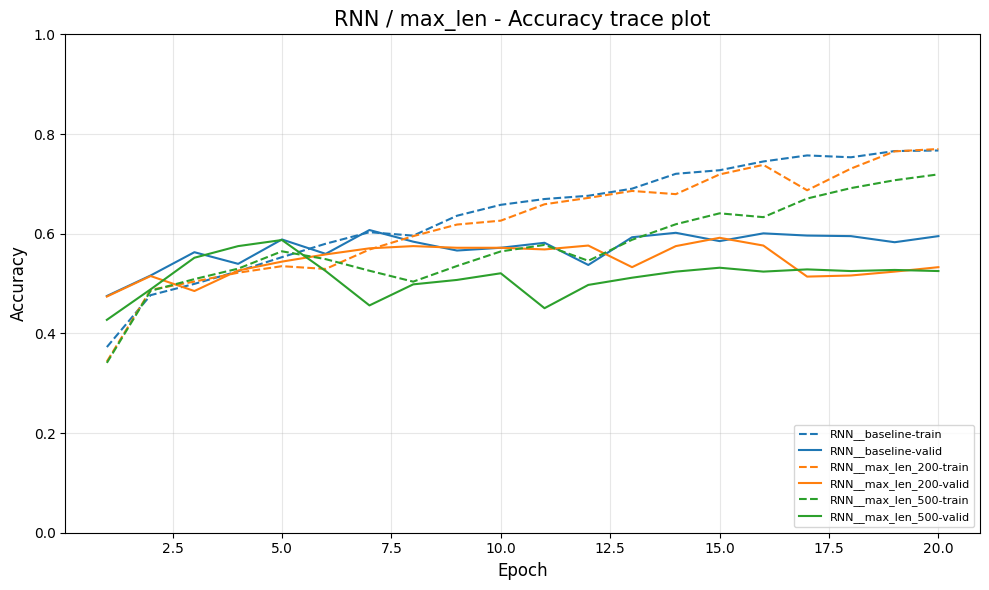

In [ ]:
results_rnn_max_len = run_parameter_experiments('RNN', 'max_len')


## 02. RNN — 은닉층 개수
이 셀은 RNN의 `layers` 후보만 비교합니다. 나머지는 기준값으로 고정합니다.


RNN / layers: 2개 설정 비교
[1/2] RNN__baseline: 테스트 손실=1.9287, 테스트 정확도=56.81%, 소요 시간=22.0초 (기존 결과 재사용)
[2/2] RNN__layers_2 학습 시작
[2/2] RNN__layers_2: 테스트 손실=2.7119, 테스트 정확도=51.29%, 소요 시간=36.8초 

테스트 결과 (기준 대비 차이는 정확도의 퍼센트포인트 차이)
          모델명 테스트 손실 테스트 정확도 기준 대비 차이(%p) 학습·평가 시간(초) 상태
RNN__baseline 1.9287  56.81%        +0.00        22.0 ok
RNN__layers_2 2.7119  51.29%        -5.52        36.8 ok


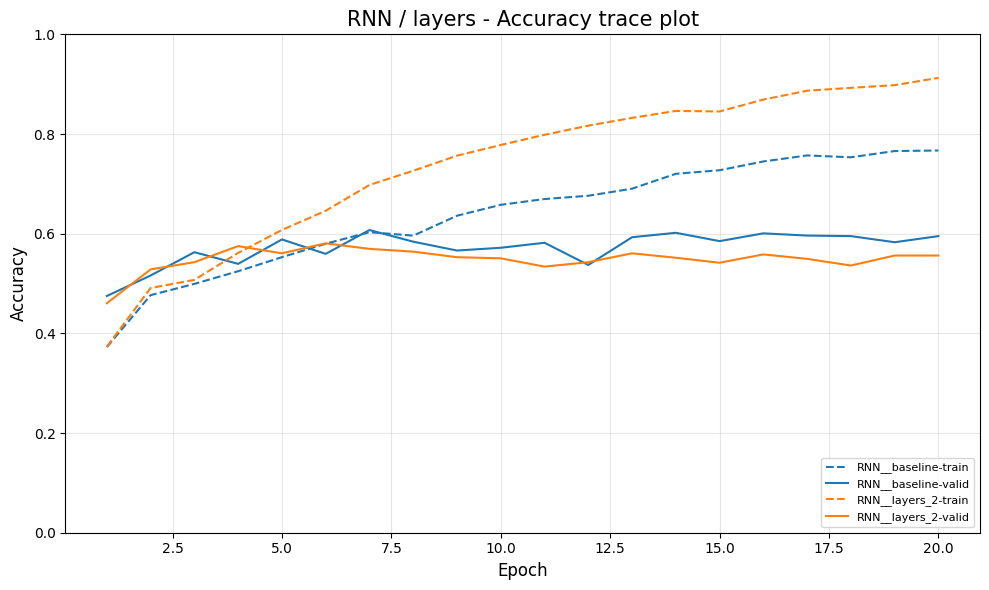

In [ ]:
results_rnn_layers = run_parameter_experiments('RNN', 'layers')


## 03. RNN — 은닉층 노드 수
이 셀은 RNN의 `units` 후보만 비교합니다. 나머지는 기준값으로 고정합니다.


RNN / units: 3개 설정 비교
[1/3] RNN__baseline: 테스트 손실=1.9287, 테스트 정확도=56.81%, 소요 시간=22.0초 (기존 결과 재사용)
[2/3] RNN__units_32 학습 시작
[2/3] RNN__units_32: 테스트 손실=2.3081, 테스트 정확도=44.57%, 소요 시간=23.4초 
[3/3] RNN__units_100 학습 시작
[3/3] RNN__units_100: 테스트 손실=2.3102, 테스트 정확도=55.83%, 소요 시간=41.5초 

테스트 결과 (기준 대비 차이는 정확도의 퍼센트포인트 차이)
           모델명 테스트 손실 테스트 정확도 기준 대비 차이(%p) 학습·평가 시간(초) 상태
 RNN__baseline 1.9287  56.81%        +0.00        22.0 ok
 RNN__units_32 2.3081  44.57%       -12.24        23.4 ok
RNN__units_100 2.3102  55.83%        -0.98        41.5 ok


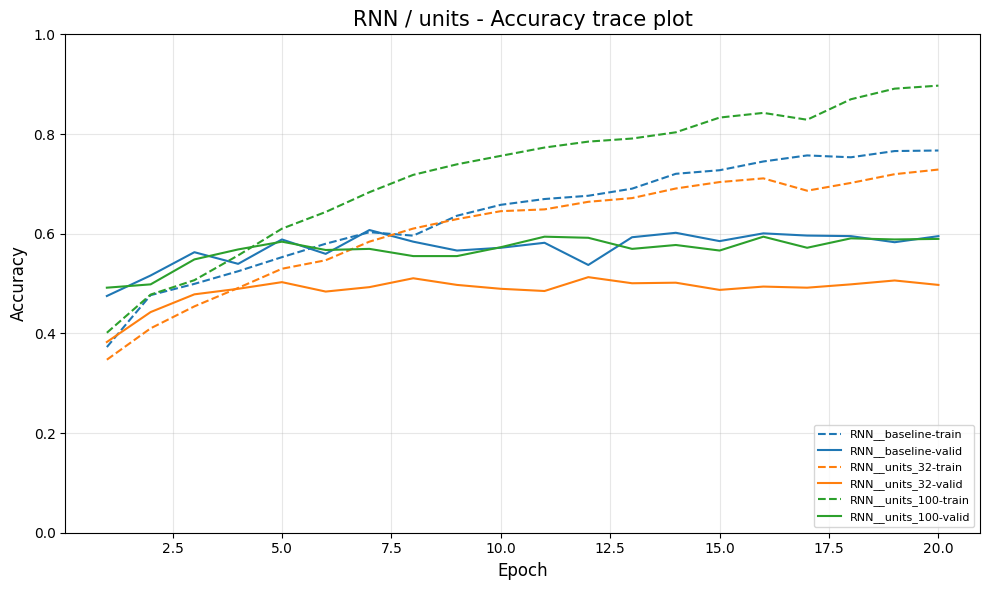

In [ ]:
results_rnn_units = run_parameter_experiments('RNN', 'units')


## 04. RNN — 최적화 방법
이 셀은 RNN의 `optimizer` 후보만 비교합니다. 나머지는 기준값으로 고정합니다.


RNN / optimizer: 3개 설정 비교
[1/3] RNN__baseline: 테스트 손실=1.9287, 테스트 정확도=56.81%, 소요 시간=22.0초 (기존 결과 재사용)
[2/3] RNN__optimizer_RMSprop 학습 시작
[2/3] RNN__optimizer_RMSprop: 테스트 손실=1.8241, 테스트 정확도=57.39%, 소요 시간=29.9초 
[3/3] RNN__optimizer_MomentumSGD 학습 시작
[3/3] RNN__optimizer_MomentumSGD: 테스트 손실=2.3837, 테스트 정확도=43.99%, 소요 시간=25.1초 

테스트 결과 (기준 대비 차이는 정확도의 퍼센트포인트 차이)
                       모델명 테스트 손실 테스트 정확도 기준 대비 차이(%p) 학습·평가 시간(초) 상태
             RNN__baseline 1.9287  56.81%        +0.00        22.0 ok
    RNN__optimizer_RMSprop 1.8241  57.39%        +0.58        29.9 ok
RNN__optimizer_MomentumSGD 2.3837  43.99%       -12.82        25.1 ok


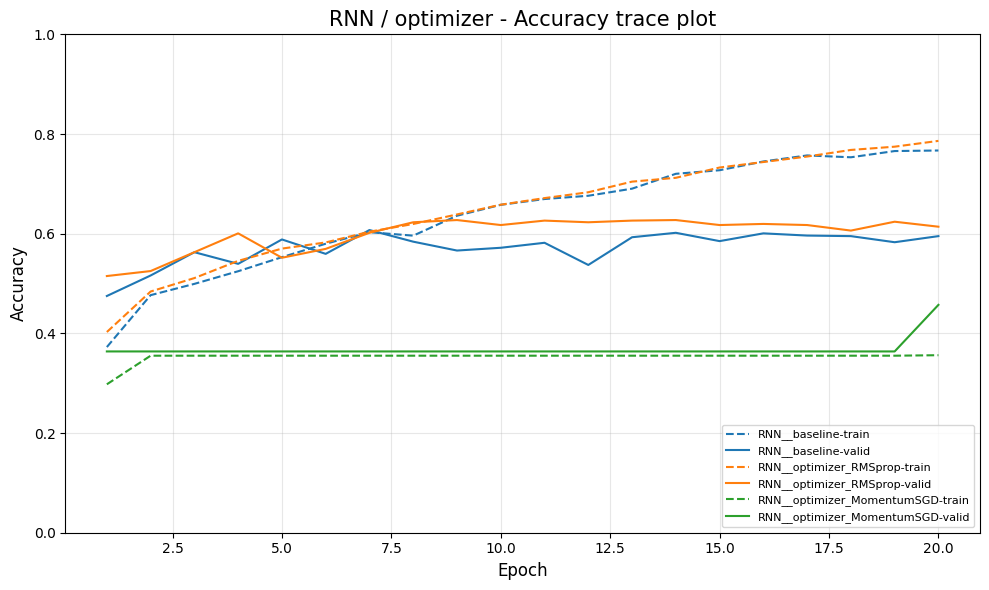

In [ ]:
results_rnn_optimizer = run_parameter_experiments('RNN', 'optimizer')


## 05. RNN — 사용할 단어 수
이 셀은 RNN의 `num_words` 후보만 비교합니다. 나머지는 기준값으로 고정합니다.


RNN / num_words: 2개 설정 비교
[1/2] RNN__baseline: 테스트 손실=1.9287, 테스트 정확도=56.81%, 소요 시간=22.0초 (기존 결과 재사용)
[2/2] RNN__num_words_5000 학습 시작
[2/2] RNN__num_words_5000: 테스트 손실=2.5228, 테스트 정확도=50.45%, 소요 시간=27.8초 

테스트 결과 (기준 대비 차이는 정확도의 퍼센트포인트 차이)
                모델명 테스트 손실 테스트 정확도 기준 대비 차이(%p) 학습·평가 시간(초) 상태
      RNN__baseline 1.9287  56.81%        +0.00        22.0 ok
RNN__num_words_5000 2.5228  50.45%        -6.37        27.8 ok


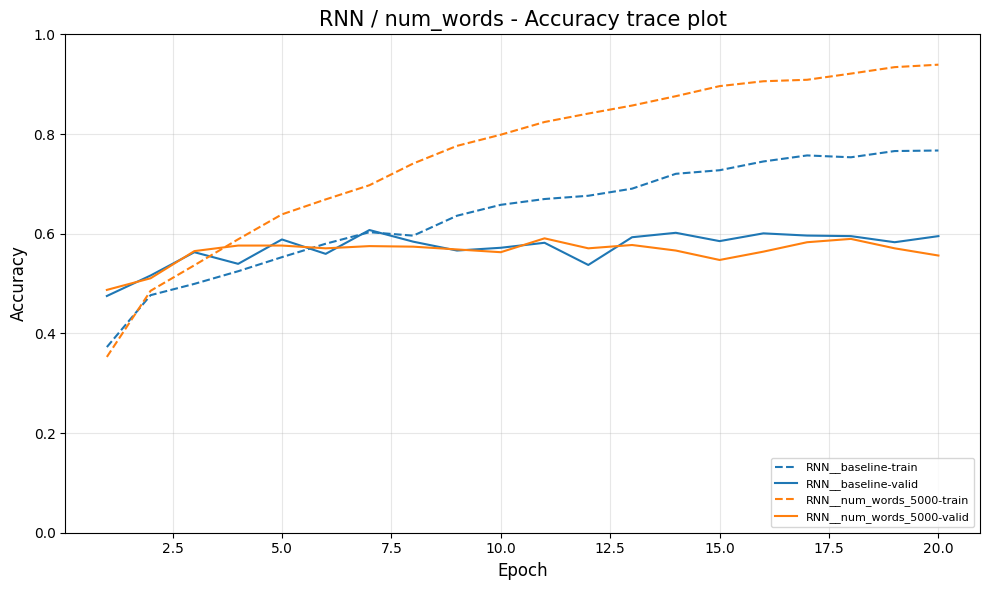

In [ ]:
results_rnn_num_words = run_parameter_experiments('RNN', 'num_words')


## 06. RNN — 임베딩 차원
이 셀은 RNN의 `embedding_dim` 후보만 비교합니다. 나머지는 기준값으로 고정합니다.


RNN / embedding_dim: 2개 설정 비교
[1/2] RNN__baseline: 테스트 손실=1.9287, 테스트 정확도=56.81%, 소요 시간=22.0초 (기존 결과 재사용)
[2/2] RNN__embedding_dim_32 학습 시작
[2/2] RNN__embedding_dim_32: 테스트 손실=2.0713, 테스트 정확도=48.17%, 소요 시간=20.7초 

테스트 결과 (기준 대비 차이는 정확도의 퍼센트포인트 차이)
                  모델명 테스트 손실 테스트 정확도 기준 대비 차이(%p) 학습·평가 시간(초) 상태
        RNN__baseline 1.9287  56.81%        +0.00        22.0 ok
RNN__embedding_dim_32 2.0713  48.17%        -8.64        20.7 ok


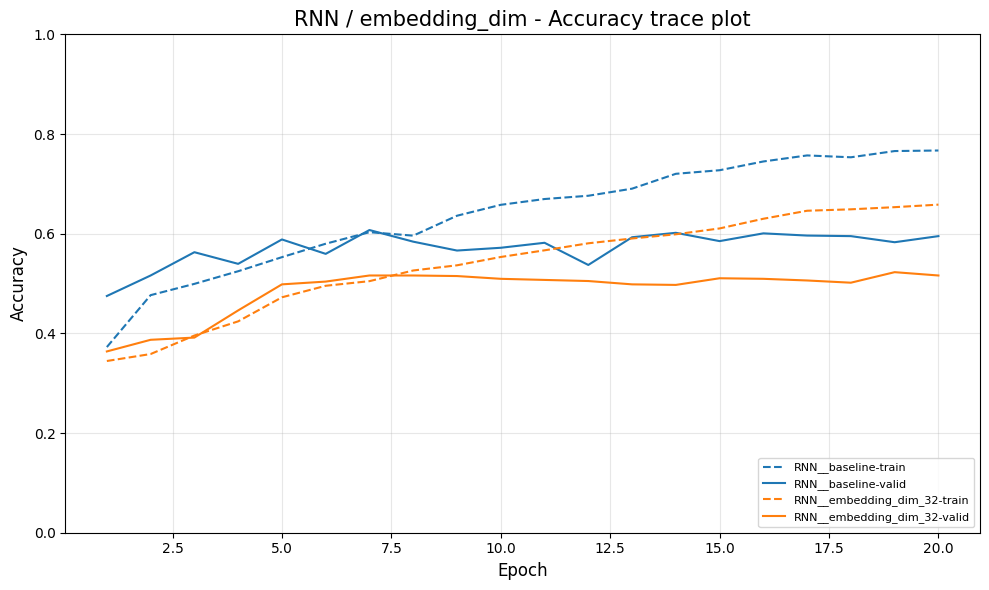

In [ ]:
results_rnn_embedding_dim = run_parameter_experiments('RNN', 'embedding_dim')


## 07. RNN — 학습률
이 셀은 RNN의 `learning_rate` 후보만 비교합니다. 나머지는 기준값으로 고정합니다.


RNN / learning_rate: 3개 설정 비교
[1/3] RNN__baseline: 테스트 손실=1.9287, 테스트 정확도=56.81%, 소요 시간=22.0초 (기존 결과 재사용)
[2/3] RNN__learning_rate_0.0001 학습 시작
[2/3] RNN__learning_rate_0.0001: 테스트 손실=1.9368, 테스트 정확도=51.20%, 소요 시간=25.7초 
[3/3] RNN__learning_rate_0.01 학습 시작
[3/3] RNN__learning_rate_0.01: 테스트 손실=2.7226, 테스트 정확도=41.81%, 소요 시간=25.4초 

테스트 결과 (기준 대비 차이는 정확도의 퍼센트포인트 차이)
                      모델명 테스트 손실 테스트 정확도 기준 대비 차이(%p) 학습·평가 시간(초) 상태
            RNN__baseline 1.9287  56.81%        +0.00        22.0 ok
RNN__learning_rate_0.0001 1.9368  51.20%        -5.61        25.7 ok
  RNN__learning_rate_0.01 2.7226  41.81%       -15.00        25.4 ok


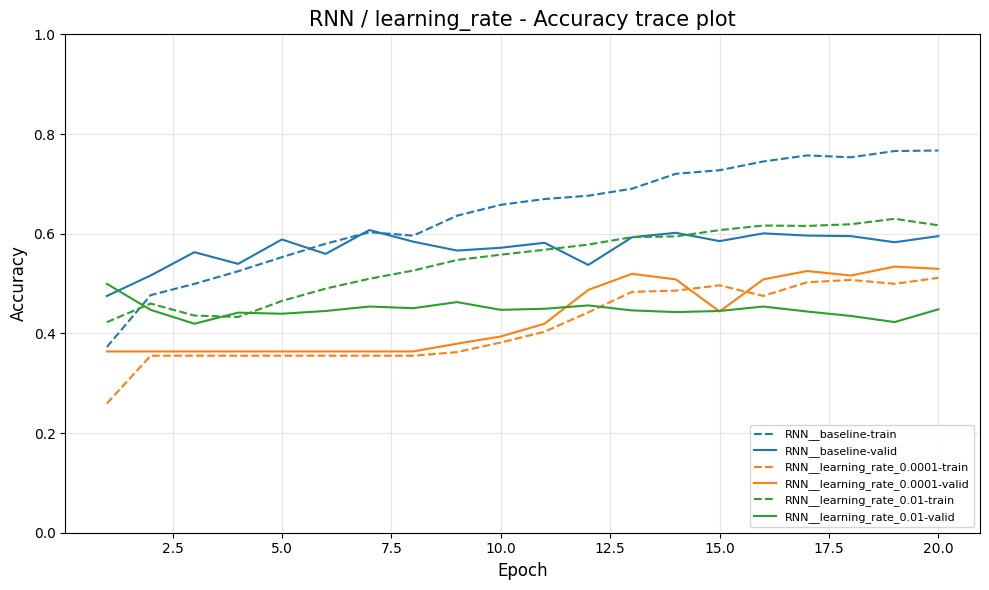

In [ ]:
results_rnn_learning_rate = run_parameter_experiments('RNN', 'learning_rate')


## 08. RNN — 배치 크기
이 셀은 RNN의 `batch_size` 후보만 비교합니다. 나머지는 기준값으로 고정합니다.


RNN / batch_size: 3개 설정 비교
[1/3] RNN__baseline: 테스트 손실=1.9287, 테스트 정확도=56.81%, 소요 시간=22.0초 (기존 결과 재사용)
[2/3] RNN__batch_size_32 학습 시작
[2/3] RNN__batch_size_32: 테스트 손실=2.4022, 테스트 정확도=52.98%, 소요 시간=47.6초 
[3/3] RNN__batch_size_256 학습 시작
[3/3] RNN__batch_size_256: 테스트 손실=1.8574, 테스트 정확도=52.89%, 소요 시간=24.1초 

테스트 결과 (기준 대비 차이는 정확도의 퍼센트포인트 차이)
                모델명 테스트 손실 테스트 정확도 기준 대비 차이(%p) 학습·평가 시간(초) 상태
      RNN__baseline 1.9287  56.81%        +0.00        22.0 ok
 RNN__batch_size_32 2.4022  52.98%        -3.83        47.6 ok
RNN__batch_size_256 1.8574  52.89%        -3.92        24.1 ok


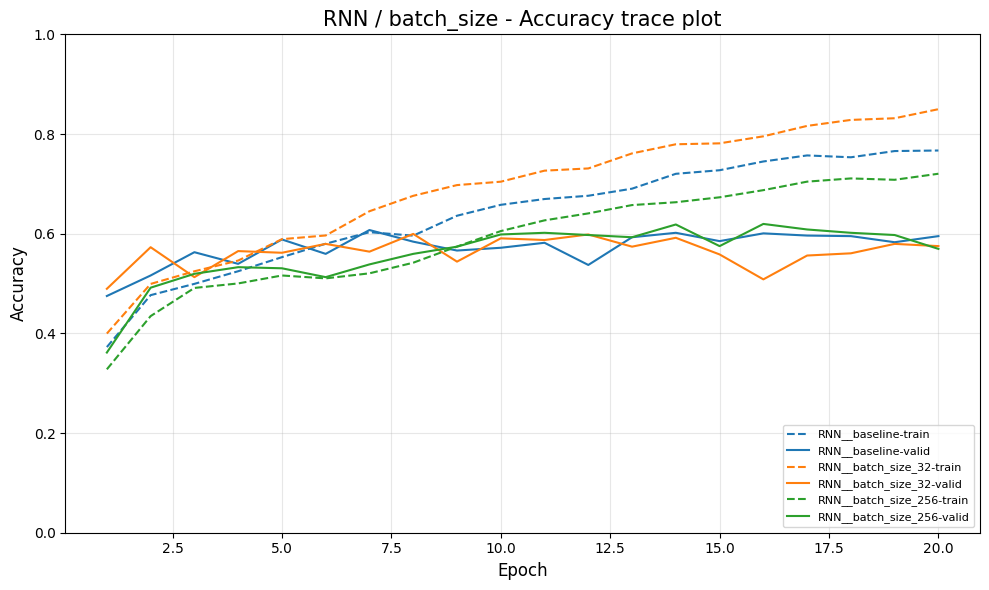

In [ ]:
results_rnn_batch_size = run_parameter_experiments('RNN', 'batch_size')


## 09. RNN — 드롭아웃
이 셀은 RNN의 `dropout` 후보만 비교합니다. 나머지는 기준값으로 고정합니다.


RNN / dropout: 2개 설정 비교
[1/2] RNN__baseline: 테스트 손실=1.9287, 테스트 정확도=56.81%, 소요 시간=22.0초 (기존 결과 재사용)
[2/2] RNN__dropout_0.2 학습 시작
[2/2] RNN__dropout_0.2: 테스트 손실=1.8675, 테스트 정확도=55.61%, 소요 시간=25.8초 

테스트 결과 (기준 대비 차이는 정확도의 퍼센트포인트 차이)
             모델명 테스트 손실 테스트 정확도 기준 대비 차이(%p) 학습·평가 시간(초) 상태
   RNN__baseline 1.9287  56.81%        +0.00        22.0 ok
RNN__dropout_0.2 1.8675  55.61%        -1.20        25.8 ok


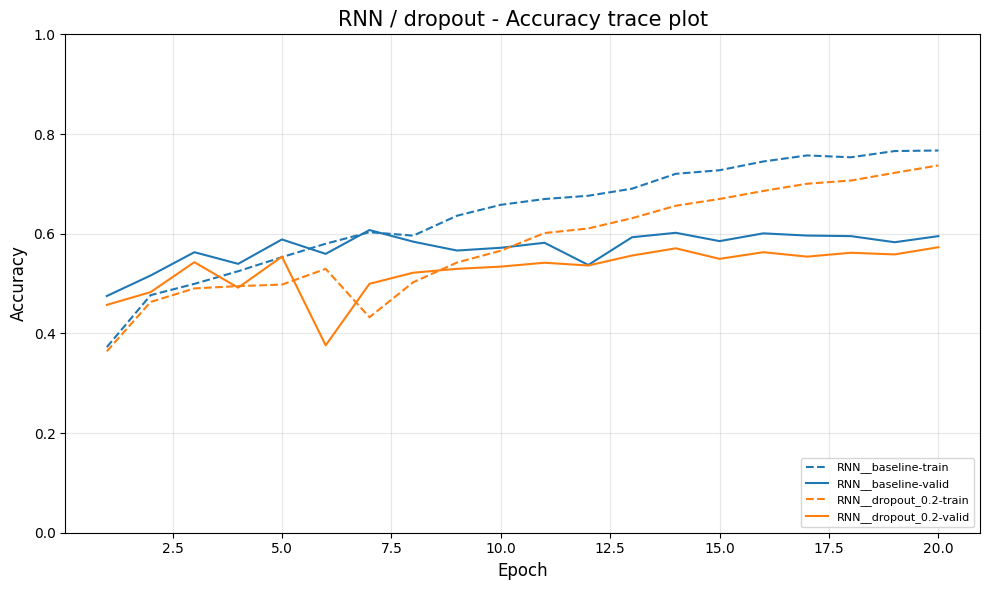

In [ ]:
results_rnn_dropout = run_parameter_experiments('RNN', 'dropout')


## 10. RNN — 학습 횟수(epoch)
이 셀은 RNN의 `epochs` 후보만 비교합니다. 나머지는 기준값으로 고정합니다.


RNN / epochs: 2개 설정 비교
[1/2] RNN__baseline: 테스트 손실=1.9287, 테스트 정확도=56.81%, 소요 시간=22.0초 (기존 결과 재사용)
[2/2] RNN__epochs_40 학습 시작
[2/2] RNN__epochs_40: 테스트 손실=2.6841, 테스트 정확도=50.85%, 소요 시간=49.1초 

테스트 결과 (기준 대비 차이는 정확도의 퍼센트포인트 차이)
           모델명 테스트 손실 테스트 정확도 기준 대비 차이(%p) 학습·평가 시간(초) 상태
 RNN__baseline 1.9287  56.81%        +0.00        22.0 ok
RNN__epochs_40 2.6841  50.85%        -5.97        49.1 ok


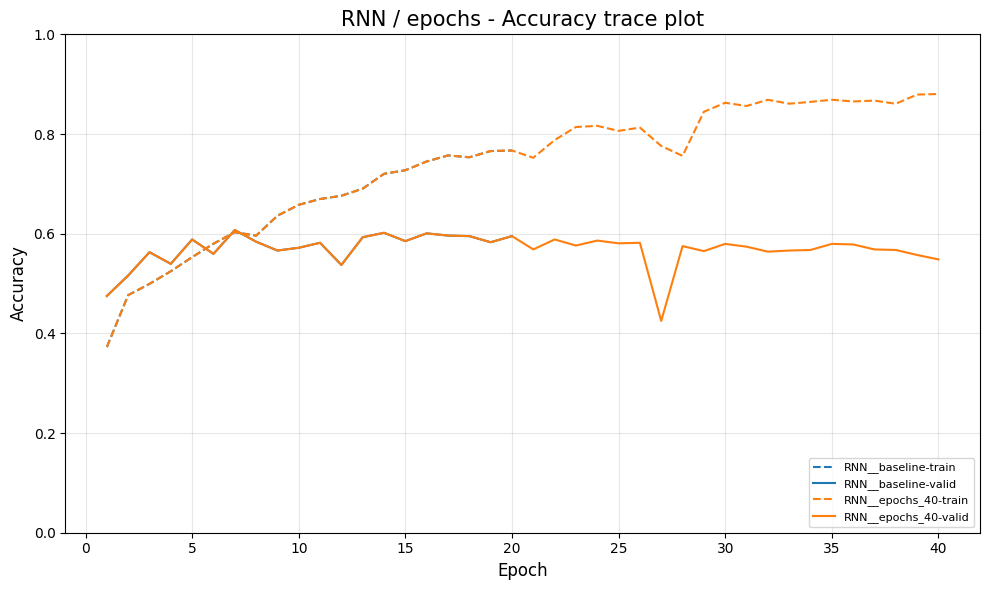

In [ ]:
results_rnn_epochs = run_parameter_experiments('RNN', 'epochs')


## 11. LSTM — 최대 길이
이 셀은 LSTM의 `max_len` 후보만 비교합니다. 나머지는 기준값으로 고정합니다.


LSTM / max_len: 3개 설정 비교
[1/3] LSTM__baseline 학습 시작
[1/3] LSTM__baseline: 테스트 손실=1.1859, 테스트 정확도=71.24%, 소요 시간=138.0초 
[2/3] LSTM__max_len_200 학습 시작
[2/3] LSTM__max_len_200: 테스트 손실=1.1245, 테스트 정확도=73.11%, 소요 시간=341.3초 
[3/3] LSTM__max_len_500 학습 시작
[3/3] LSTM__max_len_500: 테스트 손실=1.3099, 테스트 정확도=68.21%, 소요 시간=1082.7초 

테스트 결과 (기준 대비 차이는 정확도의 퍼센트포인트 차이)
              모델명 테스트 손실 테스트 정확도 기준 대비 차이(%p) 학습·평가 시간(초) 상태
   LSTM__baseline 1.1859  71.24%        +0.00       138.0 ok
LSTM__max_len_200 1.1245  73.11%        +1.87       341.3 ok
LSTM__max_len_500 1.3099  68.21%        -3.03      1082.7 ok


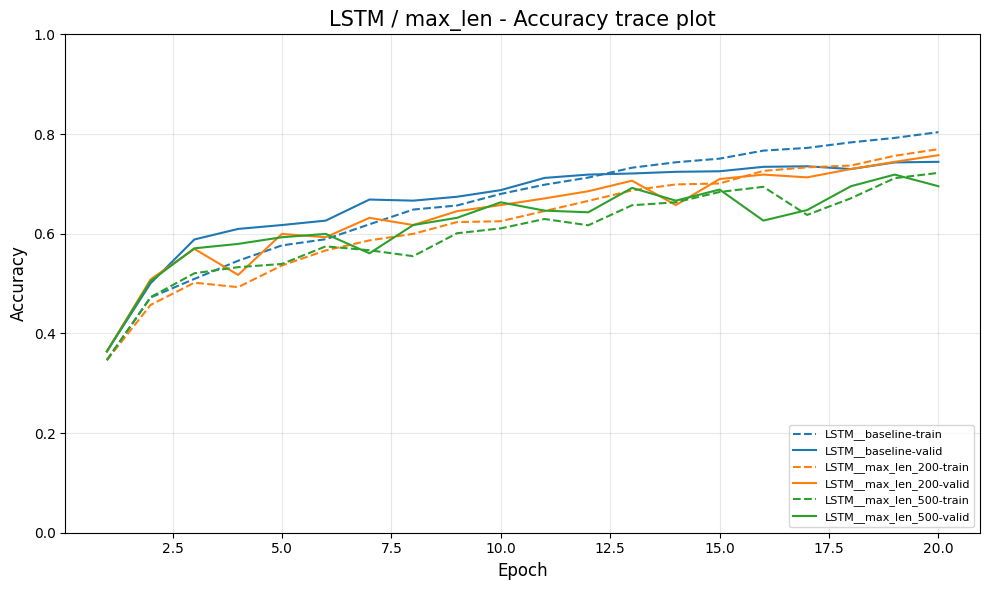

In [ ]:
results_lstm_max_len = run_parameter_experiments('LSTM', 'max_len')


## 12. LSTM — 은닉층 개수
이 셀은 LSTM의 `layers` 후보만 비교합니다. 나머지는 기준값으로 고정합니다.


LSTM / layers: 2개 설정 비교
[1/2] LSTM__baseline: 테스트 손실=1.1859, 테스트 정확도=71.24%, 소요 시간=138.0초 (기존 결과 재사용)
[2/2] LSTM__layers_2 학습 시작
[2/2] LSTM__layers_2: 테스트 손실=1.2367, 테스트 정확도=69.37%, 소요 시간=328.9초 

테스트 결과 (기준 대비 차이는 정확도의 퍼센트포인트 차이)
           모델명 테스트 손실 테스트 정확도 기준 대비 차이(%p) 학습·평가 시간(초) 상태
LSTM__baseline 1.1859  71.24%        +0.00       138.0 ok
LSTM__layers_2 1.2367  69.37%        -1.87       328.9 ok


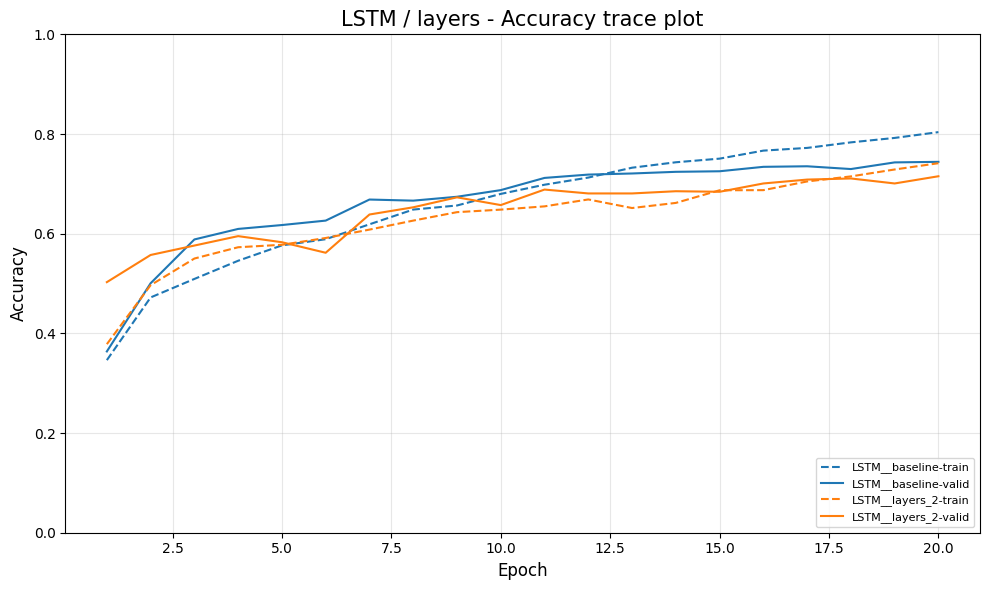

In [ ]:
results_lstm_layers = run_parameter_experiments('LSTM', 'layers')


## 13. LSTM — 은닉층 노드 수
이 셀은 LSTM의 `units` 후보만 비교합니다. 나머지는 기준값으로 고정합니다.


LSTM / units: 3개 설정 비교
[1/3] LSTM__baseline: 테스트 손실=1.1859, 테스트 정확도=71.24%, 소요 시간=138.0초 (기존 결과 재사용)
[2/3] LSTM__units_32 학습 시작
[2/3] LSTM__units_32: 테스트 손실=1.3674, 테스트 정확도=68.70%, 소요 시간=53.2초 
[3/3] LSTM__units_50 학습 시작
[3/3] LSTM__units_50: 테스트 손실=1.3411, 테스트 정확도=68.48%, 소요 시간=64.2초 

테스트 결과 (기준 대비 차이는 정확도의 퍼센트포인트 차이)
           모델명 테스트 손실 테스트 정확도 기준 대비 차이(%p) 학습·평가 시간(초) 상태
LSTM__baseline 1.1859  71.24%        +0.00       138.0 ok
LSTM__units_32 1.3674  68.70%        -2.54        53.2 ok
LSTM__units_50 1.3411  68.48%        -2.76        64.2 ok


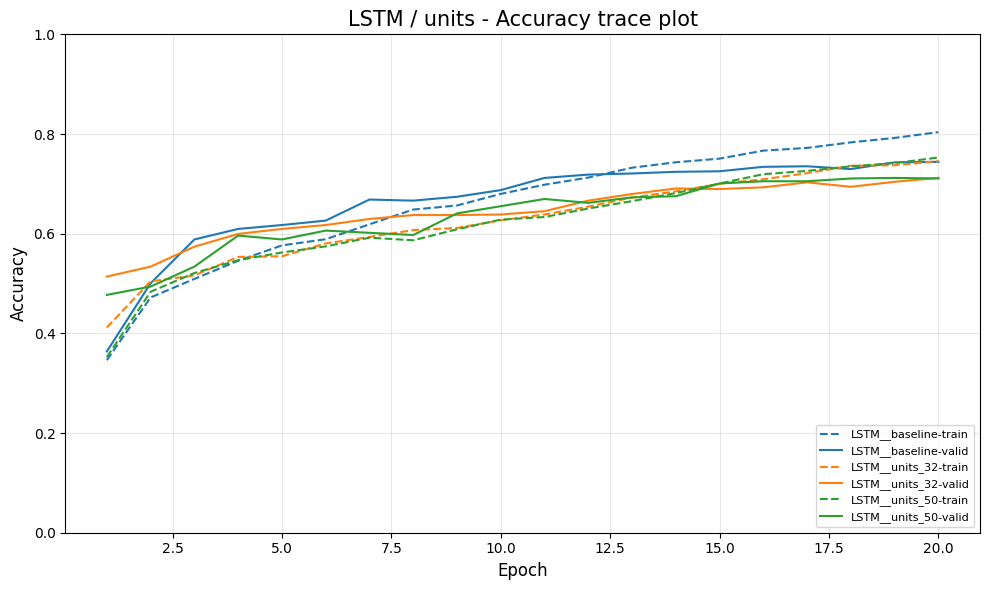

In [ ]:
results_lstm_units = run_parameter_experiments('LSTM', 'units')


## 14. LSTM — 최적화 방법
이 셀은 LSTM의 `optimizer` 후보만 비교합니다. 나머지는 기준값으로 고정합니다.


LSTM / optimizer: 3개 설정 비교
[1/3] LSTM__baseline: 테스트 손실=1.1859, 테스트 정확도=71.24%, 소요 시간=138.0초 (기존 결과 재사용)
[2/3] LSTM__optimizer_RMSprop 학습 시작
[2/3] LSTM__optimizer_RMSprop: 테스트 손실=1.2814, 테스트 정확도=68.88%, 소요 시간=141.9초 
[3/3] LSTM__optimizer_MomentumSGD 학습 시작
[3/3] LSTM__optimizer_MomentumSGD: 테스트 손실=2.4216, 테스트 정확도=34.46%, 소요 시간=140.3초 

테스트 결과 (기준 대비 차이는 정확도의 퍼센트포인트 차이)
                        모델명 테스트 손실 테스트 정확도 기준 대비 차이(%p) 학습·평가 시간(초) 상태
             LSTM__baseline 1.1859  71.24%        +0.00       138.0 ok
    LSTM__optimizer_RMSprop 1.2814  68.88%        -2.36       141.9 ok
LSTM__optimizer_MomentumSGD 2.4216  34.46%       -36.78       140.3 ok


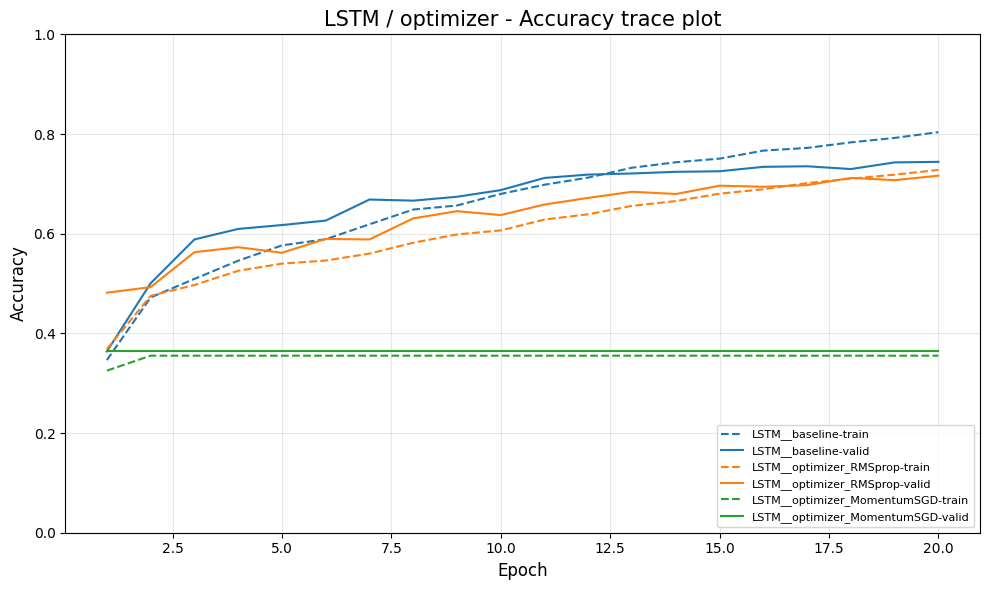

In [ ]:
results_lstm_optimizer = run_parameter_experiments('LSTM', 'optimizer')


## 15. LSTM — 사용할 단어 수
이 셀은 LSTM의 `num_words` 후보만 비교합니다. 나머지는 기준값으로 고정합니다.


LSTM / num_words: 2개 설정 비교
[1/2] LSTM__baseline: 테스트 손실=1.1859, 테스트 정확도=71.24%, 소요 시간=138.0초 (기존 결과 재사용)
[2/2] LSTM__num_words_5000 학습 시작
[2/2] LSTM__num_words_5000: 테스트 손실=1.4848, 테스트 정확도=69.10%, 소요 시간=146.8초 

테스트 결과 (기준 대비 차이는 정확도의 퍼센트포인트 차이)
                 모델명 테스트 손실 테스트 정확도 기준 대비 차이(%p) 학습·평가 시간(초) 상태
      LSTM__baseline 1.1859  71.24%        +0.00       138.0 ok
LSTM__num_words_5000 1.4848  69.10%        -2.14       146.8 ok


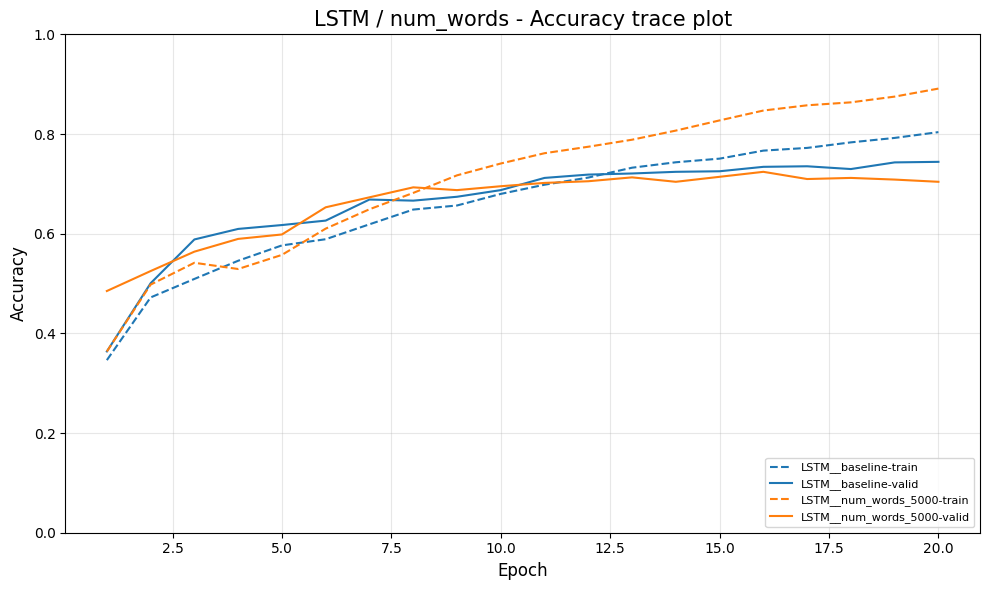

In [ ]:
results_lstm_num_words = run_parameter_experiments('LSTM', 'num_words')


## 16. LSTM — 임베딩 차원
이 셀은 LSTM의 `embedding_dim` 후보만 비교합니다. 나머지는 기준값으로 고정합니다.


LSTM / embedding_dim: 2개 설정 비교
[1/2] LSTM__baseline: 테스트 손실=1.1859, 테스트 정확도=71.24%, 소요 시간=138.0초 (기존 결과 재사용)
[2/2] LSTM__embedding_dim_32 학습 시작
[2/2] LSTM__embedding_dim_32: 테스트 손실=1.2818, 테스트 정확도=68.17%, 소요 시간=128.1초 

테스트 결과 (기준 대비 차이는 정확도의 퍼센트포인트 차이)
                   모델명 테스트 손실 테스트 정확도 기준 대비 차이(%p) 학습·평가 시간(초) 상태
        LSTM__baseline 1.1859  71.24%        +0.00       138.0 ok
LSTM__embedding_dim_32 1.2818  68.17%        -3.07       128.1 ok


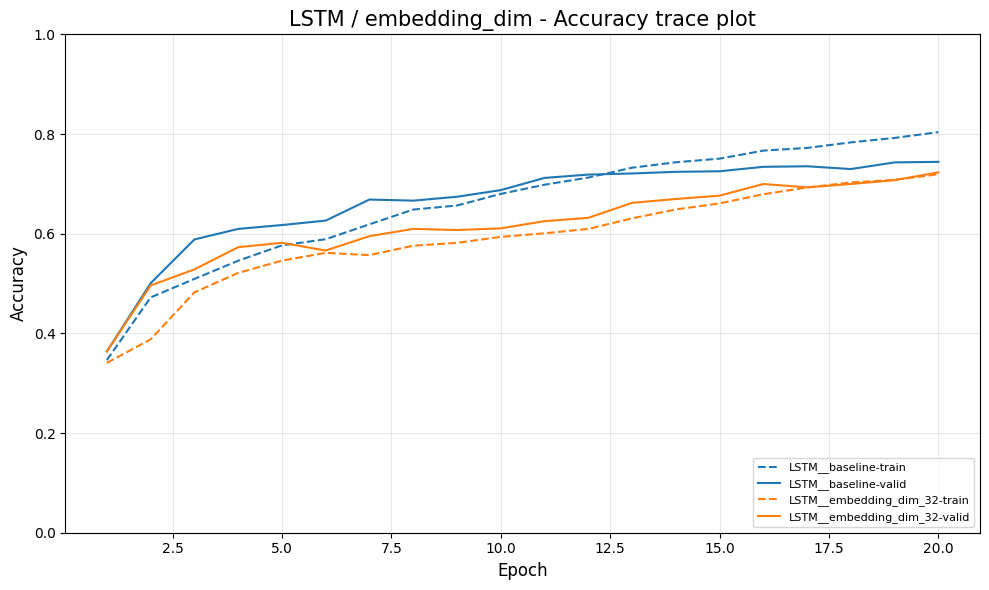

In [ ]:
results_lstm_embedding_dim = run_parameter_experiments('LSTM', 'embedding_dim')


## 17. LSTM — 학습률
이 셀은 LSTM의 `learning_rate` 후보만 비교합니다. 나머지는 기준값으로 고정합니다.


LSTM / learning_rate: 3개 설정 비교
[1/3] LSTM__baseline: 테스트 손실=1.1859, 테스트 정확도=71.24%, 소요 시간=138.0초 (기존 결과 재사용)
[2/3] LSTM__learning_rate_0.0001 학습 시작
[2/3] LSTM__learning_rate_0.0001: 테스트 손실=1.7043, 테스트 정확도=56.68%, 소요 시간=143.3초 
[3/3] LSTM__learning_rate_0.01 학습 시작
[3/3] LSTM__learning_rate_0.01: 테스트 손실=1.7348, 테스트 정확도=70.61%, 소요 시간=142.1초 

테스트 결과 (기준 대비 차이는 정확도의 퍼센트포인트 차이)
                       모델명 테스트 손실 테스트 정확도 기준 대비 차이(%p) 학습·평가 시간(초) 상태
            LSTM__baseline 1.1859  71.24%        +0.00       138.0 ok
LSTM__learning_rate_0.0001 1.7043  56.68%       -14.56       143.3 ok
  LSTM__learning_rate_0.01 1.7348  70.61%        -0.62       142.1 ok


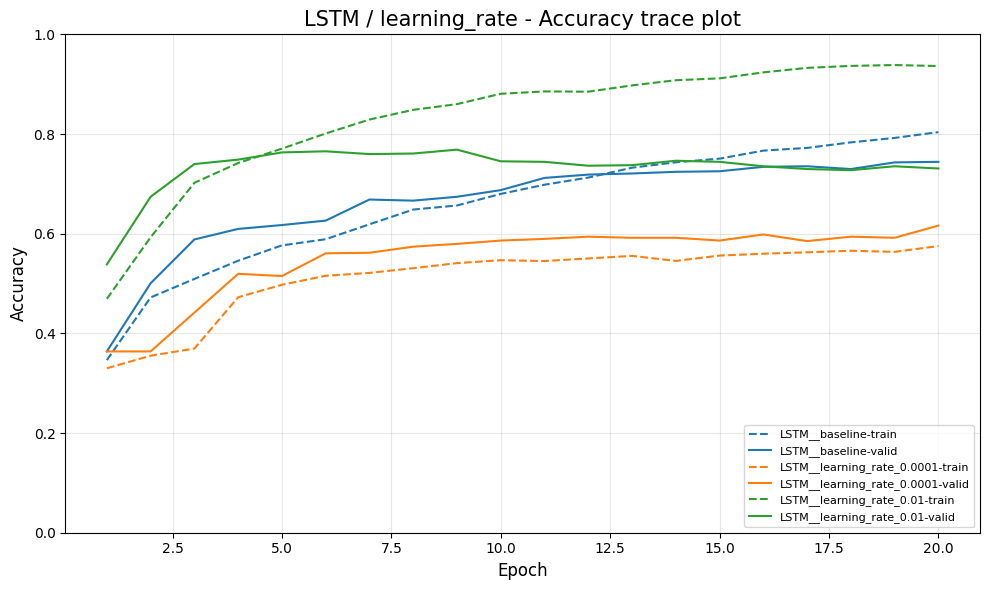

In [ ]:
results_lstm_learning_rate = run_parameter_experiments('LSTM', 'learning_rate')


## 18. LSTM — 배치 크기
이 셀은 LSTM의 `batch_size` 후보만 비교합니다. 나머지는 기준값으로 고정합니다.


LSTM / batch_size: 3개 설정 비교
[1/3] LSTM__baseline: 테스트 손실=1.1859, 테스트 정확도=71.24%, 소요 시간=138.0초 (기존 결과 재사용)
[2/3] LSTM__batch_size_32 학습 시작
[2/3] LSTM__batch_size_32: 테스트 손실=1.3447, 테스트 정확도=72.35%, 소요 시간=190.3초 
[3/3] LSTM__batch_size_256 학습 시작
[3/3] LSTM__batch_size_256: 테스트 손실=1.3380, 테스트 정확도=67.01%, 소요 시간=121.1초 

테스트 결과 (기준 대비 차이는 정확도의 퍼센트포인트 차이)
                 모델명 테스트 손실 테스트 정확도 기준 대비 차이(%p) 학습·평가 시간(초) 상태
      LSTM__baseline 1.1859  71.24%        +0.00       138.0 ok
 LSTM__batch_size_32 1.3447  72.35%        +1.11       190.3 ok
LSTM__batch_size_256 1.3380  67.01%        -4.23       121.1 ok


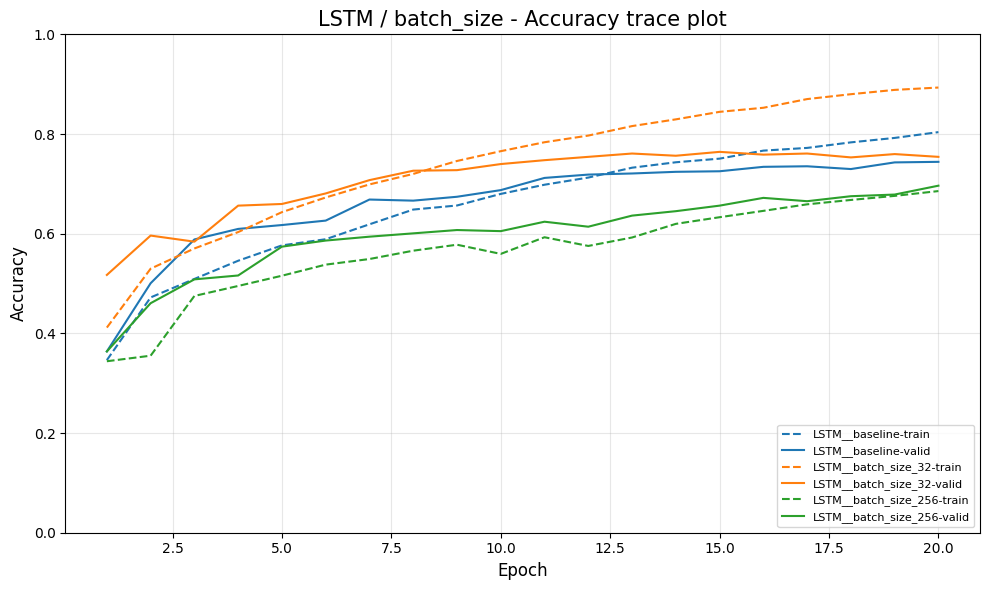

In [ ]:
results_lstm_batch_size = run_parameter_experiments('LSTM', 'batch_size')


## 19. LSTM — 드롭아웃
이 셀은 LSTM의 `dropout` 후보만 비교합니다. 나머지는 기준값으로 고정합니다.


LSTM / dropout: 2개 설정 비교
[1/2] LSTM__baseline: 테스트 손실=1.1859, 테스트 정확도=71.24%, 소요 시간=138.0초 (기존 결과 재사용)
[2/2] LSTM__dropout_0.2 학습 시작
[2/2] LSTM__dropout_0.2: 테스트 손실=1.2735, 테스트 정확도=69.86%, 소요 시간=163.5초 

테스트 결과 (기준 대비 차이는 정확도의 퍼센트포인트 차이)
              모델명 테스트 손실 테스트 정확도 기준 대비 차이(%p) 학습·평가 시간(초) 상태
   LSTM__baseline 1.1859  71.24%        +0.00       138.0 ok
LSTM__dropout_0.2 1.2735  69.86%        -1.38       163.5 ok


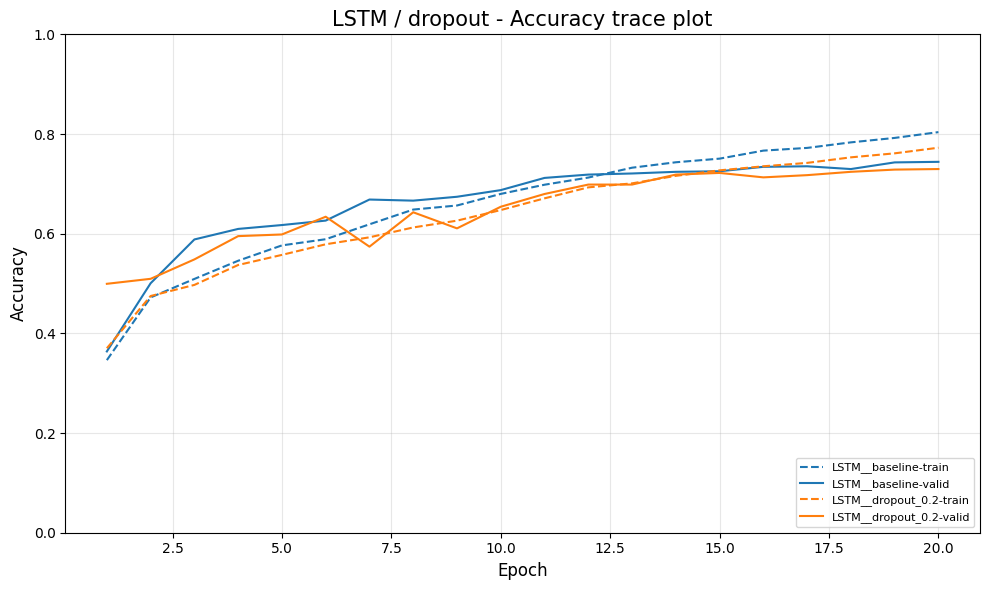

In [ ]:
results_lstm_dropout = run_parameter_experiments('LSTM', 'dropout')


## 20. LSTM — 학습 횟수(epoch)
이 셀은 LSTM의 `epochs` 후보만 비교합니다. 나머지는 기준값으로 고정합니다.


LSTM / epochs: 2개 설정 비교
[1/2] LSTM__baseline: 테스트 손실=1.1859, 테스트 정확도=71.24%, 소요 시간=138.0초 (기존 결과 재사용)
[2/2] LSTM__epochs_40 학습 시작
[2/2] LSTM__epochs_40: 테스트 손실=1.5044, 테스트 정확도=71.59%, 소요 시간=317.6초 

테스트 결과 (기준 대비 차이는 정확도의 퍼센트포인트 차이)
            모델명 테스트 손실 테스트 정확도 기준 대비 차이(%p) 학습·평가 시간(초) 상태
 LSTM__baseline 1.1859  71.24%        +0.00       138.0 ok
LSTM__epochs_40 1.5044  71.59%        +0.36       317.6 ok


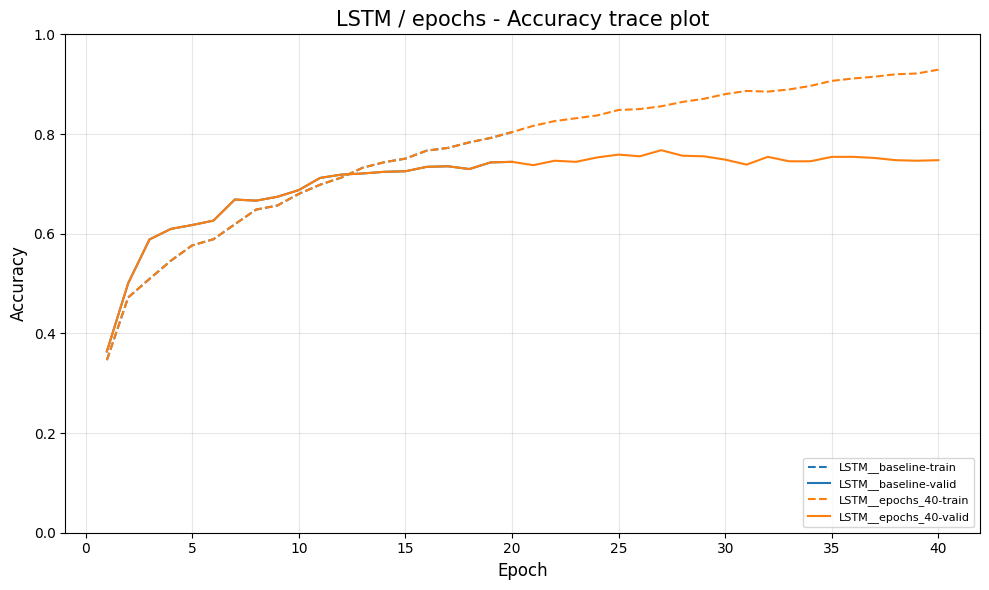

In [ ]:
results_lstm_epochs = run_parameter_experiments('LSTM', 'epochs')
